# Sinusoidal positions and rotary embeddings

Why can an attention head recognise a separation of three tokens after both tokens move? Compare an absolute sinusoidal code with a rotation of a query and a key.

Each pair of channels has its own angular frequency. The inner product of two rotated vectors depends on the difference between their positions. This experiment holds both content vectors fixed so that the position effect can be measured.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    for column in frame.columns:
        if "error" in column.lower() or column == "Change in query norm":
            frame[column] = frame[column].map(lambda value: f"{value:.2e}")
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


def softmax(logits, axis=-1):
    shifted = logits - np.max(logits, axis=axis, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=axis, keepdims=True)


def angles(positions, width):
    return np.asarray(positions)[..., None] * 10000.0 ** (-np.arange(0, width, 2) / width)


def rotary(vector, positions):
    pair = vector.reshape(-1, 2)
    value = angles(positions, vector.size)
    c, s = np.cos(value), np.sin(value)
    a, b = pair[:, 0], pair[:, 1]
    return np.stack((a * c - b * s, a * s + b * c), axis=-1).reshape(
        (*value.shape[:-1], vector.size)
    )

## Test relative position directly

Apply the same global shifts to both positions. Inner products should agree to floating-point precision.

In [2]:
rng = np.random.default_rng(17)
width = 16
q, k = rng.normal(size=(2, width))
positions = np.arange(40)
gaps = np.arange(16)
baseline = rotary(q, 0) @ rotary(k, gaps).T
rows = []
for shift in (0, 3, 11, 37):
    scores = rotary(q, shift) @ rotary(k, shift + gaps).T
    rows.append(
        (
            shift,
            np.max(np.abs(scores - baseline)),
            np.linalg.norm(rotary(q, shift)) - np.linalg.norm(q),
        )
    )
assert max(row[1] for row in rows) < 1e-11
report(["Shared shift", "Max dot-product error", "Change in query norm"], rows)

,Shared shift,Max dot-product error,Change in query norm
0,0,0.00e+00,0.00e+00
1,3,3.55e-15,0.00e+00
2,11,4.44e-15,0.00e+00
3,37,3.55e-15,0.00e+00


## Compare the position maps

Left, colour encodes a coordinate of the original position embedding. Right, diagonals have the same query-key separation.

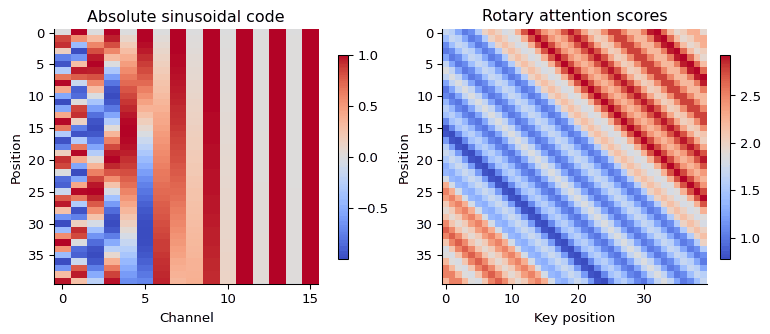

In [3]:
a = angles(positions, width)
encoding = np.stack((np.sin(a), np.cos(a)), axis=-1).reshape(len(positions), width)
scores = rotary(q, positions) @ rotary(k, positions).T / np.sqrt(width)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4), layout="constrained")
for ax, arr, title, x in zip(
    axes,
    [encoding, scores],
    ["Absolute sinusoidal code", "Rotary attention scores"],
    ["Channel", "Key position"],
):
    im = ax.imshow(arr, aspect="auto", cmap="coolwarm")
    ax.set(title=title, xlabel=x, ylabel="Position")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## Interpreting the result

The diagonals stay level because the vectors entering the rotation are fixed. With different token content, scores along a diagonal can vary.

## Exercise

Repeat the common shift test after adding absolute positions to the content vectors. Which terms in the expanded dot product change?

## References

[Vaswani et al. (2017), Attention Is All You Need](https://arxiv.org/abs/1706.03762)

[Su et al. (2021), RoFormer](https://arxiv.org/abs/2104.09864)